In [180]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [181]:
df=pd.read_csv('daily-website-visitors.csv')
df.drop('Row',axis=1,inplace=True)

In [182]:
display(df.head())

,Day,Day_Of_Week,Date,Page_Loads,Unique_Visits,First_Time_Visits,Returning_Visits
0,Sunday,1,9/14/2014,"2,146","1,582","1,430",152
1,Monday,2,9/15/2014,"3,621","2,528","2,297",231
2,Tuesday,3,9/16/2014,"3,698","2,630","2,352",278
3,Wednesday,4,9/17/2014,"3,667","2,614","2,327",287
4,Thursday,5,9/18/2014,"3,316","2,366","2,130",236


In [183]:
df.isna().sum()

Day                  0
Day_Of_Week          0
Date                 0
Page_Loads           0
Unique_Visits        0
First_Time_Visits    0
Returning_Visits     0
dtype: int64

In [184]:
df.dtypes

Day                    str
Day_Of_Week          int64
Date                   str
Page_Loads             str
Unique_Visits          str
First_Time_Visits      str
Returning_Visits       str
dtype: object

In [185]:
def delete_comma(a):
    return int(str(a).replace(",", ""))

In [186]:
need_change_type=['Page_Loads','Unique_Visits','First_Time_Visits','Returning_Visits']

for col in need_change_type:
    df[col]=df[col].apply(delete_comma)
    
df['Date']=pd.to_datetime(df['Date'])

In [187]:
df.dtypes

Day                             str
Day_Of_Week                   int64
Date                 datetime64[us]
Page_Loads                    int64
Unique_Visits                 int64
First_Time_Visits             int64
Returning_Visits              int64
dtype: object

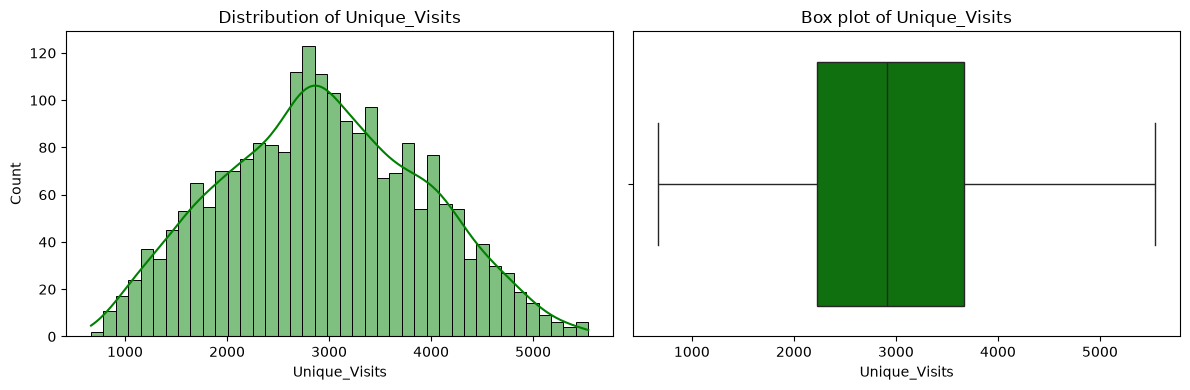

In [188]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Unique_Visits"], bins=40, kde=True, color="green", ax=axes[0])
axes[0].set_title("Distribution of Unique_Visits")

sns.boxplot(x=df["Unique_Visits"], color="green", ax=axes[1])
axes[1].set_title("Box plot of Unique_Visits")

plt.tight_layout()
plt.show()

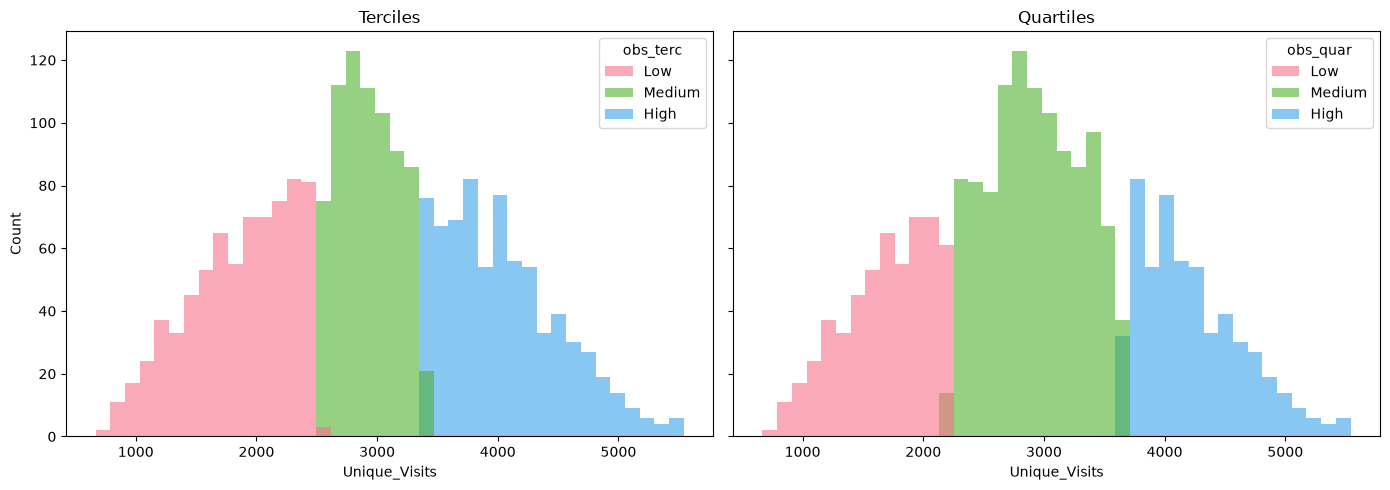

In [189]:
v = df["Unique_Visits"]
names = {0: "Low", 1: "Medium", 2: "High"}

df["obs_terc"] = pd.qcut(df["Unique_Visits"], q=3, labels=[0, 1, 2]).astype(int)
df["obs_quar"] = pd.qcut(df["Unique_Visits"], q=[0, 0.25, 0.75, 1], labels=[0, 1, 2]).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.histplot(x=v, hue=df["obs_terc"].map(names), hue_order=["Low", "Medium", "High"],
             bins=40, alpha=0.6, linewidth=0, ax=axes[0])
axes[0].set_title("Terciles")

sns.histplot(x=v, hue=df["obs_quar"].map(names), hue_order=["Low", "Medium", "High"],
             bins=40, alpha=0.6, linewidth=0, ax=axes[1])
axes[1].set_title("Quartiles")

plt.tight_layout()
plt.show()

In [190]:
df["obs_quar"].value_counts().rename(index=names)

obs_quar
Medium    1082
Low        543
High       542
Name: count, dtype: int64

In [191]:
df['obs_terc'].value_counts().rename(index=names)

obs_terc
Low       723
Medium    722
High      722
Name: count, dtype: int64

In [192]:
df = df.drop(columns="obs_quar").rename(columns={"obs_terc": "visits"})

df['visits_str']=df['visits'].map(names)